1. DEMONSTRATED HYPERPARAMETER TUNING SEARCH
  Logistic Regression C=0.01 -> Mean Grouped CV AUC: 0.9469
  Logistic Regression C=0.1 -> Mean Grouped CV AUC: 0.9489
  Logistic Regression C=1.0 -> Mean Grouped CV AUC: 0.9496
  Logistic Regression C=10.0 -> Mean Grouped CV AUC: 0.9494
==> Selected Best C for Logistic Regression: 1.0

2. TRACEABLE 5-FOLD GROUPED CV EVALUATION
                              Model         ROC-AUC          PR-AUC        F1-Score Precision Recall    ECE Fit Time/Fold
    Logistic Regression (L2, C=1.0) 0.9523 ± 0.0073 0.9485 ± 0.0089 0.8845 ± 0.0166    0.8708 0.8989 0.0327        1.25 s
Random Forest (500 trees, depth=16) 0.9684 ± 0.0045 0.9704 ± 0.0051 0.9006 ± 0.0106    0.9181 0.8839 0.0465       18.10 s
 XGBoost (Tuned Classical Baseline) 0.9711 ± 0.0032 0.9723 ± 0.0042 0.8987 ± 0.0120    0.9058 0.8919 0.0262       13.62 s
 ResNet-MLP (Temp. Scaled, Level 2) 0.9659 ± 0.0046 0.9676 ± 0.0054 0.8909 ± 0.0090    0.9065 0.8760 0.0211       14.54 s
3. AUTOMATED SU

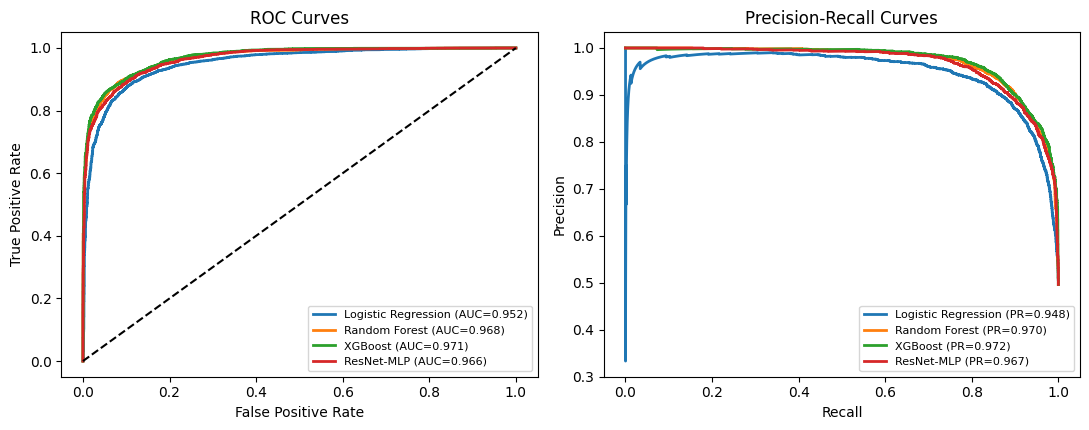

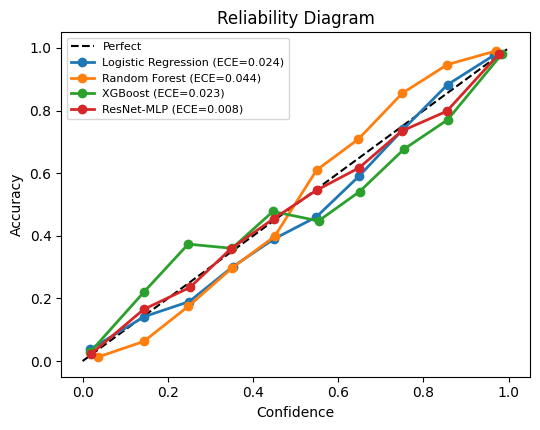

In [1]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, roc_curve, precision_recall_curve
)
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

DATA_PATH = "data/cumulative.csv"
NASA_TAP_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+*+from+cumulative&format=csv"

if not os.path.exists(DATA_PATH):
    df = pd.read_csv(NASA_TAP_URL)
    df.to_csv(DATA_PATH, index=False)
else:
    df = pd.read_csv(DATA_PATH, comment="#")

df["target"] = (df["koi_disposition"] != "FALSE POSITIVE").astype(int)
y = df["target"].values
groups = df["kepid"].values

LEAKAGE_COLS = ["koi_disposition", "koi_pdisposition", "koi_score", "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
ID_METADATA_COLS = ["rowid", "kepid", "kepoi_name", "kepler_name", "koi_tce_delivname", "koi_datalink_dvr", "koi_datalink_dvs", "koi_sparprov", "koi_vet_stat", "koi_vet_date", "koi_disp_prov", "koi_comment", "koi_fittype", "koi_limbdark_mod", "koi_parm_prov", "koi_trans_mod", "koi_quarters"]

drop_set = set(LEAKAGE_COLS + ID_METADATA_COLS + ["target"])

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
dev_idx, test_idx = next(gss.split(df, y, groups=groups))
df_dev = df.iloc[dev_idx].reset_index(drop=True)
df_test = df.iloc[test_idx].reset_index(drop=True)

y_dev = df_dev["target"].values
groups_dev = df_dev["kepid"].values

train_missing_rate = df_dev.isna().mean()
candidate_num_cols = [c for c in df_dev.select_dtypes(include=[np.number]).columns if c not in drop_set and train_missing_rate[c] < 0.50]

X_dev = df_dev[candidate_num_cols].copy()
expected_depth_ppm = ((X_dev["koi_prad"] / (109.076 * X_dev["koi_srad"])) ** 2) * 1e6
X_dev["eng_depth_radius_consistency"] = X_dev["koi_depth"] / (expected_depth_ppm + 1.0)
X_dev["eng_duty_cycle"] = (X_dev["koi_duration"] / 24.0) / (X_dev["koi_period"] + 1e-6)

SKEW_COLS = ["koi_period", "koi_depth", "koi_prad", "koi_insol", "koi_model_snr", "koi_duration"]
for col in SKEW_COLS:
    if col in X_dev.columns:
        X_dev[f"log_{col}"] = np.log1p(np.clip(X_dev[col], a_min=0, a_max=None))

def compute_ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    binids = np.digitize(y_prob, bins) - 1
    ece = 0.0
    for i in range(n_bins):
        mask = binids == i
        if np.any(mask):
            ece += np.abs(np.mean(y_true[mask]) - np.mean(y_prob[mask])) * (np.sum(mask) / len(y_true))
    return ece

def fit_temperature_scaling(logits, y_true):
    def bce_loss(T):
        t = T[0]
        p = 1.0 / (1.0 + np.exp(-np.clip(logits / t, -50, 50)))
        p = np.clip(p, 1e-7, 1.0 - 1e-7)
        return -np.mean(y_true * np.log(p) + (1.0 - y_true) * np.log(1.0 - p))
    res = minimize(bce_loss, x0=[1.0], bounds=[(0.05, 10.0)], method="L-BFGS-B")
    return res.x[0]

print("1. DEMONSTRATED HYPERPARAMETER TUNING SEARCH")
best_C, best_lr_auc = 0.1, 0.0
gkf_tune = GroupKFold(n_splits=3)
for c_val in [0.01, 0.1, 1.0, 10.0]:
    aucs = []
    for tr_i, va_i in gkf_tune.split(X_dev, y_dev, groups=groups_dev):
        pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(C=c_val, max_iter=1000, random_state=SEED))
        ])
        pipe.fit(X_dev.iloc[tr_i], y_dev[tr_i])
        preds = pipe.predict_proba(X_dev.iloc[va_i])[:, 1]
        aucs.append(roc_auc_score(y_dev[va_i], preds))
    mean_auc = np.mean(aucs)
    print(f"  Logistic Regression C={c_val} -> Mean Grouped CV AUC: {mean_auc:.4f}")
    if mean_auc > best_lr_auc:
        best_lr_auc = mean_auc
        best_C = c_val
print(f"==> Selected Best C for Logistic Regression: {best_C}\n")

class ResidualBlock(nn.Module):
    def __init__(self, dim, dropout=0.25):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(dim, dim), nn.BatchNorm1d(dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(dim, dim), nn.BatchNorm1d(dim)
        )
        self.relu = nn.ReLU()
    def forward(self, x):
        return self.relu(x + self.fc(x))

class ExoplanetResNetMLP(nn.Module):
    def __init__(self, in_features, hidden_dim=128, dropout=0.25):
        super().__init__()
        self.stem = nn.Sequential(nn.Linear(in_features, hidden_dim), nn.BatchNorm1d(hidden_dim), nn.ReLU())
        self.block1 = ResidualBlock(hidden_dim, dropout)
        self.head = nn.Sequential(nn.Linear(hidden_dim, 64), nn.ReLU(), nn.Dropout(dropout), nn.Linear(64, 1))
    def forward(self, x):
        return self.head(self.block1(self.stem(x))).squeeze(-1)

def train_resnet_fold(X_tr, y_tr, X_va, y_va, epochs=50, batch_size=128, lr=1e-3):
    prep = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)), ("scaler", StandardScaler())])
    X_tr_s, X_va_s = prep.fit_transform(X_tr), prep.transform(X_va)
    model = ExoplanetResNetMLP(X_tr_s.shape[1], hidden_dim=128, dropout=0.25)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()
    loader = DataLoader(TensorDataset(torch.tensor(X_tr_s, dtype=torch.float32), torch.tensor(y_tr, dtype=torch.float32)), batch_size=batch_size, shuffle=True)

    best_va_loss, best_va_logits = float("inf"), None
    for epoch in range(epochs):
        model.train()
        for bx, by in loader:
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            va_logits = model(torch.tensor(X_va_s, dtype=torch.float32))
            va_loss = criterion(va_logits, torch.tensor(y_va, dtype=torch.float32)).item()
        if va_loss < best_va_loss:
            best_va_loss = va_loss
            best_va_logits = va_logits.numpy()
    return best_va_logits

print("2. TRACEABLE 5-FOLD GROUPED CV EVALUATION")
gkf = GroupKFold(n_splits=5)
models_to_evaluate = {
    f"Logistic Regression (L2, C={best_C})": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(C=best_C, max_iter=1000, random_state=SEED))
    ]),
    "Random Forest (500 trees, depth=16)": Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("clf", RandomForestClassifier(n_estimators=500, max_depth=16, max_features="sqrt", n_jobs=-1, random_state=SEED))
    ]),
    "XGBoost (Tuned Classical Baseline)": XGBClassifier(
        n_estimators=500, learning_rate=0.03, max_depth=6, reg_lambda=5.0, gamma=0.5,
        subsample=0.8, colsample_bytree=0.8, eval_metric="logloss", n_jobs=-1, random_state=SEED
    )
}

results_summary = []
oof_probs = {}

for name, model in models_to_evaluate.items():
    fold_aucs, fold_prs, fold_f1s, fold_prec, fold_rec, fold_eces, fold_times = [], [], [], [], [], [], []
    oof = np.zeros(len(X_dev))

    for tr_idx, va_idx in gkf.split(X_dev, y_dev, groups=groups_dev):
        X_tr, y_tr = X_dev.iloc[tr_idx], y_dev[tr_idx]
        X_va, y_va = X_dev.iloc[va_idx], y_dev[va_idx]

        start_time = time.time()
        model.fit(X_tr, y_tr)
        fold_times.append(time.time() - start_time)

        probs = model.predict_proba(X_va)[:, 1]
        oof[va_idx] = probs

        fold_aucs.append(roc_auc_score(y_va, probs))
        fold_prs.append(average_precision_score(y_va, probs))
        preds = (probs >= 0.5).astype(int)
        fold_f1s.append(f1_score(y_va, preds))
        fold_prec.append(precision_score(y_va, preds))
        fold_rec.append(recall_score(y_va, preds))
        fold_eces.append(compute_ece(y_va, probs))

    oof_probs[name] = oof
    results_summary.append({
        "Model": name,
        "ROC-AUC": f"{np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}",
        "PR-AUC": f"{np.mean(fold_prs):.4f} ± {np.std(fold_prs):.4f}",
        "F1-Score": f"{np.mean(fold_f1s):.4f} ± {np.std(fold_f1s):.4f}",
        "Precision": f"{np.mean(fold_prec):.4f}",
        "Recall": f"{np.mean(fold_rec):.4f}",
        "ECE": f"{np.mean(fold_eces):.4f}",
        "Fit Time/Fold": f"{np.mean(fold_times):.2f} s"
    })

rn_fold_aucs, rn_fold_prs, rn_fold_f1s, rn_fold_prec, rn_fold_rec, rn_fold_eces, rn_fold_times = [], [], [], [], [], [], []
oof_rn = np.zeros(len(X_dev))

for tr_idx, va_idx in gkf.split(X_dev, y_dev, groups=groups_dev):
    X_tr, y_tr = X_dev.iloc[tr_idx], y_dev[tr_idx]
    X_va, y_va = X_dev.iloc[va_idx], y_dev[va_idx]

    start_time = time.time()
    va_logits = train_resnet_fold(X_tr, y_tr, X_va, y_va)
    fold_duration = time.time() - start_time
    rn_fold_times.append(fold_duration)

    half = len(va_idx) // 2
    T_opt = fit_temperature_scaling(va_logits[:half], y_va[:half])
    cal_probs = 1.0 / (1.0 + np.exp(-np.clip(va_logits / T_opt, -50, 50)))

    oof_rn[va_idx] = cal_probs
    rn_fold_aucs.append(roc_auc_score(y_va, cal_probs))
    rn_fold_prs.append(average_precision_score(y_va, cal_probs))
    preds = (cal_probs >= 0.5).astype(int)
    rn_fold_f1s.append(f1_score(y_va, preds))
    rn_fold_prec.append(precision_score(y_va, preds))
    rn_fold_rec.append(recall_score(y_va, preds))
    rn_fold_eces.append(compute_ece(y_va, cal_probs))

oof_probs["ResNet-MLP (Temp. Scaled)"] = oof_rn
results_summary.append({
    "Model": "ResNet-MLP (Temp. Scaled, Level 2)",
    "ROC-AUC": f"{np.mean(rn_fold_aucs):.4f} ± {np.std(rn_fold_aucs):.4f}",
    "PR-AUC": f"{np.mean(rn_fold_prs):.4f} ± {np.std(rn_fold_prs):.4f}",
    "F1-Score": f"{np.mean(rn_fold_f1s):.4f} ± {np.std(rn_fold_f1s):.4f}",
    "Precision": f"{np.mean(rn_fold_prec):.4f}",
    "Recall": f"{np.mean(rn_fold_rec):.4f}",
    "ECE": f"{np.mean(rn_fold_eces):.4f}",
    "Fit Time/Fold": f"{np.mean(rn_fold_times):.2f} s"
})

print(pd.DataFrame(results_summary).to_string(index=False))

print("3. AUTOMATED SUBGROUP ERROR ANALYSIS")
xgb_oof_preds = (oof_probs["XGBoost (Tuned Classical Baseline)"] >= 0.5).astype(int)
error_mask = (xgb_oof_preds != y_dev)
low_snr_mask = (X_dev["koi_model_snr"] < 12)
high_snr_mask = (X_dev["koi_model_snr"] > 50)
missing_radius_mask = X_dev["koi_srad"].isna()

print(f"Total development samples: {len(y_dev)}")
print(f"  - Low SNR (<12) error rate: {error_mask[low_snr_mask].mean()*100:.2f}% ({low_snr_mask.sum()} samples)")
print(f"  - High SNR (>50) error rate: {error_mask[high_snr_mask].mean()*100:.2f}% ({high_snr_mask.sum()} samples)")
print(f"  - Missing stellar radius error rate: {error_mask[missing_radius_mask].mean()*100:.2f}% ({missing_radius_mask.sum()} samples)")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for name, p in oof_probs.items():
    fpr, tpr, _ = roc_curve(y_dev, p)
    prec, rec, _ = precision_recall_curve(y_dev, p)
    axes[0].plot(fpr, tpr, lw=2, label=f"{name.split(' (')[0]} (AUC={roc_auc_score(y_dev, p):.3f})")
    axes[1].plot(rec, prec, lw=2, label=f"{name.split(' (')[0]} (PR={average_precision_score(y_dev, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curves")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curves")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/fig1_roc_pr_curves.png", dpi=300)

plt.figure(figsize=(5.5, 4.4))
plt.plot([0, 1], [0, 1], "k--", label="Perfect")
for name, p in oof_probs.items():
    pt, pp = calibration_curve(y_dev, p, n_bins=10)
    plt.plot(pp, pt, marker="o", lw=2, label=f"{name.split(' (')[0]} (ECE={compute_ece(y_dev, p):.3f})")
plt.xlabel("Confidence")
plt.ylabel("Accuracy")
plt.title("Reliability Diagram")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/fig2_diagnostics_calibration.png", dpi=300)
print("\nGenerated and saved updated traceable figures successfully!")